In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

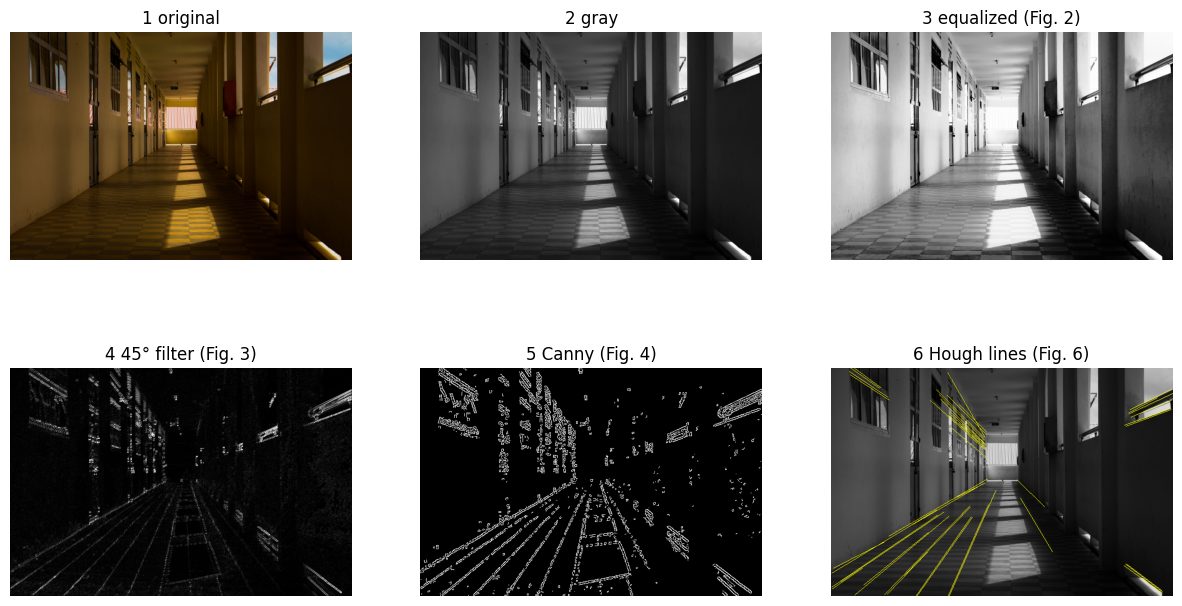

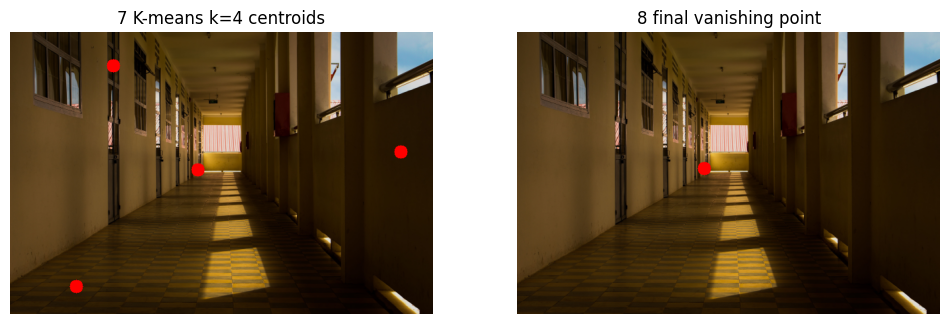

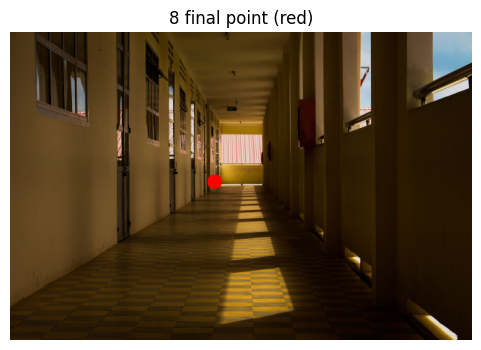

[[156.95     52.15   ]
 [284.90002 209.96667]
 [591.05554 182.55556]
 [100.55    385.75   ]] [[283.3639  207.60556]]


In [52]:
### 1. Načítanie obrázka
chodba = cv.imread('./imgs/chodba1.jpg')
#chodba = cv.imread('./imgs/chodba2.jpg')
#chodba = cv.imread('./imgs/chodba3.jpg')

scale = 640 / chodba.shape[1]
chodba = cv.resize(chodba, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
H, W = chodba.shape[:2]

### 2. Šedotónová konverzia
chodba_gray = cv.cvtColor(chodba, cv.COLOR_BGR2GRAY)

### 3. Ekvalizácia histo
chodba_eq = cv.equalizeHist(chodba_gray)

### 4. 45 stupňová maska
kernel = np.array([[-1,-1,2],[-1,2,-1],[2,-1,-1]], dtype=np.float32)
filtered = cv.filter2D(chodba_eq, cv.CV_32F, kernel)
chodba_45 = cv.convertScaleAbs(filtered)

### 5. Cannyho detekcia hran
threshold1 = 90
threshold2 = 150
edges = cv.Canny(chodba_45, threshold1, threshold2)

### 6. Hough transformácia
lines = cv.HoughLinesP(edges, rho=1, theta=np.pi/180, threshold=100, minLineLength=50, maxLineGap=10)
lines = lines.reshape(-1, 4)

chodba_lines = cv.cvtColor(chodba_gray, cv.COLOR_GRAY2BGR)

for x1, y1, x2, y2 in lines:
  cv.line(chodba_lines, (x1,y1), (x2,y2), (0, 255, 255), 1)

### 7. K-means (k=4)
points = np.vstack([lines[:, 0:2], lines[:, 2:4]]).astype(np.float32)

criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels, centers4 = cv.kmeans(points, 4, None, criteria, 10, cv.KMEANS_PP_CENTERS)

marker_r = max(5, W //60)
chodba_k4 = chodba.copy()
for cx, cy in centers4:
    cv.circle(chodba_k4, (int(cx), int(cy)), marker_r, (0, 0, 255), -1)

### 8. K-means (k=1)

_, labels, centers1 = cv.kmeans(centers4.astype(np.float32), 1, None, criteria, 10, cv.KMEANS_PP_CENTERS)

chodba_k1 = chodba.copy()
for cx, cy in centers1:
    cv.circle(chodba_k1, (int(cx), int(cy)), marker_r, (0, 0, 255), -1)

### Finalny vystup

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.ravel()
ax[0].imshow(cv.cvtColor(chodba, cv.COLOR_BGR2RGB)); ax[0].set_title('1 original')
ax[1].imshow(chodba_gray, cmap='gray');               ax[1].set_title('2 gray')
ax[2].imshow(chodba_eq, cmap='gray');                 ax[2].set_title('3 equalized (Fig. 2)')
ax[3].imshow(chodba_45, cmap='gray');                 ax[3].set_title('4 45° filter (Fig. 3)')
ax[4].imshow(edges, cmap='gray');                     ax[4].set_title('5 Canny (Fig. 4)')
ax[5].imshow(cv.cvtColor(chodba_lines, cv.COLOR_BGR2RGB)); ax[5].set_title('6 Hough lines (Fig. 6)')
for a in ax: a.axis('off')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(cv.cvtColor(chodba_k4, cv.COLOR_BGR2RGB)); ax[0].set_title('7 K-means k=4 centroids')
ax[1].imshow(cv.cvtColor(chodba_k1, cv.COLOR_BGR2RGB)); ax[1].set_title('8 final vanishing point')
for a in ax: a.axis('off')
plt.show()

plt.figure(figsize=(6, 4))
plt.imshow(cv.cvtColor(chodba_k1, cv.COLOR_BGR2RGB))
plt.title('8 final point (red)')
plt.axis('off')
plt.show()
print(centers4, centers1)


